# Exploratory Data Analysis on Superstore Retail Sales

## Internship
Datheon – Data Analytics & Power BI Internship

## Objective
To perform exploratory data analysis on the Superstore Retail Sales dataset to understand sales performance, profitability, customer purchasing patterns, and business trends.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

Libraries imported successfully!
Dataset loaded successfully!
  Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
1      2  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
2      3  CA-2017-138688   6/12/2017   6/16/2017    Second Class    DV-13045   
3      4  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
4      5  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product 

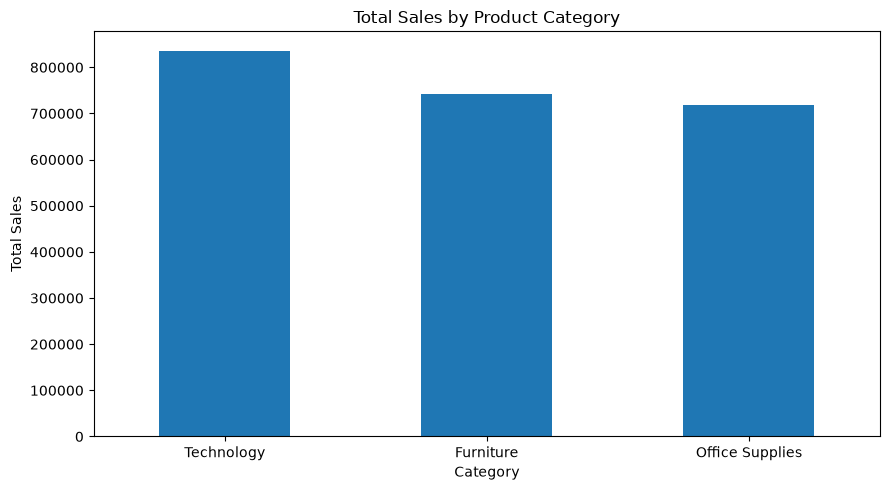

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

df = pd.read_csv("superstore_sales.csv")

print("Dataset loaded successfully!")
print(df.head())
print(df.tail())
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Columns:")

for column in df.columns:
    print(column)
print(df.info())
print(df.describe(include='all'))
print("Column Data Types:")
print(df.dtypes)

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

print(missing_summary)

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

df = df.drop_duplicates()

print("Duplicate records removed successfully!")
print("Updated Dataset Shape:", df.shape)

if 'Postal Code' in df.columns:
    df['Postal Code'] = df['Postal Code'].fillna('Unknown')

print("Missing Postal Codes handled successfully!")
print("Remaining Missing Values:", df.isnull().sum().sum())

date_columns = ['Order Date', 'Ship Date']

for column in date_columns:
    df[column] = pd.to_datetime(
        df[column],
        format='%m/%d/%Y',
        errors='coerce'
    )

print("Date columns converted successfully!")
print(df[date_columns].dtypes)

for column in date_columns:
    print(column, "Invalid Dates:", df[column].isnull().sum())

df['Year'] = df['Order Date'].dt.year

print("Year column created successfully!")
print(df[['Order Date', 'Year']].head())
df['Month'] = df['Order Date'].dt.month_name()

print("Month column created successfully!")
print(df[['Order Date', 'Month']].head())

df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

print("Year-Month column created successfully!")
print(df[['Order Date', 'Year', 'Month', 'Year-Month']].head())

print(df.head())
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())
total_sales = df['Sales'].sum()

print("Total Sales:", round(total_sales, 2))

total_profit = df['Profit'].sum()

print("Total Profit:", round(total_profit, 2))
total_quantity = df['Quantity'].sum()

print("Total Quantity Sold:", total_quantity)
average_sales = df['Sales'].mean()
average_profit = df['Profit'].mean()

print("Average Sales:", round(average_sales, 2))
print("Average Profit:", round(average_profit, 2))
profit_margin = (total_profit / total_sales) * 100

print("Overall Profit Margin:", round(profit_margin, 2), "%")

category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

print("Sales by Category:")
print(category_sales)

category_profit = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)

print("Profit by Category:")
print(category_profit)

plt.figure(figsize=(9, 5))

category_sales.plot(kind='bar')

plt.title('Total Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()